## Read embeddings

In [1]:
import pandas as pd
MODELS_DESCRIPTIONS = {
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10]
        },
    "mix_of_alleles_balanced":
    {
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "path": "experiment_results/alleles_with_groups_balanced/",
        "states": 25,
        "params_string": "5-min_iters",
        "target_lengths": [9, 10]
    }

}
selected_model = MODELS_DESCRIPTIONS["mix_of_alleles"]


In [2]:

selected_alleles = selected_model['alleles']
states = selected_model['states']
TARGET_LENGTHS = selected_model['target_lengths']
selected_combination = "+".join(selected_alleles).replace('-', '_').replace('*', '_').replace(':', '_')
selected_model_split = 0 # should match to data split (if original train/test used) in order to have true test case
selected_model_run = 0
target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])

In [3]:
mixed_model_bw =f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'
mixed_model_bwv = f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}_plus_viterbi'
mixed_model_v = f'{selected_model_run}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'

name_to_model_root = dict()
name_to_model_root[mixed_model_bw] = selected_model['path']
name_to_model_root[mixed_model_bwv] = selected_model['path']
name_to_model_root[mixed_model_v] = selected_model['path']

In [4]:
def load_embeddings(model):
    print(f"model {model}")
    TARGET_PATH_TO_FILES = name_to_model_root[model] + model
    # Train 
    train_df =  pd.read_csv("{}/train_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)
    # Test 
    test_df =  pd.read_csv("{}/test_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)

    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
    return  train_df, test_df


In [5]:
%%time
per_model_type_train_embeddings = dict()
per_model_type_test_embeddings = dict()
# BW
train_df, test_df = load_embeddings(mixed_model_bw)
per_model_type_train_embeddings['bw'] = train_df
per_model_type_test_embeddings['bw'] = test_df
# BWV
train_df, test_df = load_embeddings(mixed_model_bwv)
per_model_type_train_embeddings['bwv'] = train_df
per_model_type_test_embeddings['bwv'] = test_df
# V
train_df, test_df = load_embeddings(mixed_model_v)
per_model_type_train_embeddings['v'] = train_df
per_model_type_test_embeddings['v'] = test_df

model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
CPU times: total: 22.2 s
Wall time: 22.4 s


# Scanpy

In [6]:
target_df = per_model_type_train_embeddings['v']

In [7]:
dropped_columns = target_df.drop(columns=['allele', 'peptide']).copy()
transposed = dropped_columns.T.copy()

In [8]:
target_df

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,allele,peptide
SFDIQLTSV,-0.741333,-0.743363,-0.599239,-0.598056,-0.655910,-0.740446,-0.654749,-0.810727,-0.804032,-0.792347,...,-0.869699,-0.811024,-0.698746,-0.899624,-0.827158,-0.574980,-0.618497,-0.768838,HLA-A*01:01,SFDIQLTSV
TTEILRSML,-0.850125,-0.766289,-0.797033,-0.766250,-0.851580,-0.813579,-0.918266,-0.745049,-0.924443,-0.849128,...,-0.670397,-0.767908,-0.802194,-0.765462,-0.678086,-0.949854,-0.946066,-0.803005,HLA-A*01:01,TTEILRSML
ALNDTWKMEK,-0.785261,-0.787291,-0.865119,-0.793308,-0.786716,-0.767572,-0.791179,-0.731933,-0.822566,-0.712815,...,-0.824822,-0.768332,-0.812263,-0.838906,-0.764201,-0.759783,-0.874332,-0.783336,HLA-A*03:01,ALNDTWKMEK
ALAAAAAAAK,-0.745589,-0.747619,-0.750961,-0.667196,-0.747044,-0.731821,-0.817246,-0.679798,-0.791407,-0.781346,...,-0.752563,-0.680347,-0.797719,-0.807747,-0.811486,-0.863721,-0.863066,-0.812680,HLA-A*03:01,ALAAAAAAAK
LYDKDAVYV,-0.731589,-0.649055,-0.901477,-0.900295,-0.733044,-0.731263,-0.803247,-0.650098,-0.794288,-0.943168,...,-0.744144,-0.864760,-0.772707,-0.726063,-0.819229,-0.849653,-0.801010,-0.899525,HLA-A*01:01,LYDKDAVYV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FIFQSSMTK,-0.818858,-0.820888,-0.636457,-0.711252,-0.820313,-0.823442,-0.732173,-0.742320,-0.783256,-0.740536,...,-0.830638,-0.664821,-0.763445,-0.875573,-0.583074,-0.767043,-0.757246,-0.845214,HLA-A*03:01,FIFQSSMTK
QLYKEQLAK,-0.607266,-0.699464,-0.726154,-0.645982,-0.698889,-0.624011,-0.633590,-0.539785,-0.571664,-0.637363,...,-0.693647,-0.828803,-0.814027,-0.678171,-0.800819,-0.628176,-0.706878,-0.697653,HLA-A*03:01,QLYKEQLAK
LLNRPLWAK,-0.727636,-0.794605,-0.708539,-0.636728,-0.790706,-0.737462,-0.641052,-0.669725,-0.692033,-0.659180,...,-0.665353,-0.708070,-0.757338,-0.773312,-0.729164,-0.637061,-0.595944,-0.771862,HLA-A*03:01,LLNRPLWAK
KVPVVLLKK,-0.678520,-0.770718,-0.514552,-0.507436,-0.770143,-0.691170,-0.591937,-0.694476,-0.642918,-0.783749,...,-0.737113,-0.735094,-0.787354,-0.829304,-0.797820,-0.628857,-0.625069,-0.706933,HLA-A*03:01,KVPVVLLKK


In [9]:
import scanpy as sc
import anndata as ad
import numpy as np

In [10]:
obs = pd.DataFrame({"peptide": target_df.index.values, "allele": target_df['allele'].values, "length": target_df.index.str.len().values})
var = pd.DataFrame({"path":target_df.columns.drop(['allele', 'peptide'])})
X = np.exp(target_df.drop(columns=['allele', 'peptide']).values)

In [11]:
adata = ad.AnnData(X, obs=obs, var=var, dtype='float')

d:\tools\python\anaconda\envs\biopython\lib\site-packages\anndata\_core\anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [12]:
adata

AnnData object with n_obs × n_vars = 13336 × 2000
    obs: 'peptide', 'allele', 'length'
    var: 'path'

In [13]:
adata.obs

,peptide,allele,length
0,SFDIQLTSV,HLA-A*01:01,9
1,TTEILRSML,HLA-A*01:01,9
2,ALNDTWKMEK,HLA-A*03:01,10
3,ALAAAAAAAK,HLA-A*03:01,10
4,LYDKDAVYV,HLA-A*01:01,9
...,...,...,...
13331,FIFQSSMTK,HLA-A*03:01,9
13332,QLYKEQLAK,HLA-A*03:01,9
13333,LLNRPLWAK,HLA-A*03:01,9
13334,KVPVVLLKK,HLA-A*03:01,9


In [14]:
adata.var

,path
0,0
1,1
2,2
3,3
4,4
...,...
1995,1995
1996,1996
1997,1997
1998,1998


In [15]:
adata.X

array([[0.47647827, 0.47551198, 0.54922951, ..., 0.56271612, 0.53875334,
        0.46355154],
       [0.42736145, 0.46473464, 0.45066424, ..., 0.38679745, 0.38826559,
        0.4479809 ],
       [0.45600056, 0.4550758 , 0.42100128, ..., 0.46776814, 0.41714042,
        0.45687953],
       ...,
       [0.48304971, 0.45175976, 0.49236303, ..., 0.52884421, 0.55104205,
        0.46215177],
       [0.50736716, 0.46268065, 0.59776812, ..., 0.5332007 , 0.53522453,
        0.49315429],
       [0.42925831, 0.42838779, 0.51708393, ..., 0.44112405, 0.47599085,
        0.43316287]])

## 1. Normalize

In [16]:
sc.pp.normalize_total(adata) # Total-count normalize (library-size correct) the data matrix X to 10,000 reads per cell, so that counts become comparable among cells.
sc.pp.log1p(adata) # log-normalization

In [17]:
adata.X

array([[0.38173274, 0.38108901, 0.42904609, ..., 0.43757629, 0.4223694 ,
        0.37308659],
       [0.36514259, 0.39154249, 0.38168498, ..., 0.3356773 , 0.33675902,
        0.37979399],
       [0.38603171, 0.38538204, 0.36114444, ..., 0.39426217, 0.35836074,
        0.38664883],
       ...,
       [0.38381449, 0.36295157, 0.38994111, ..., 0.41358461, 0.42770219,
        0.36992895],
       [0.39678229, 0.36751168, 0.45349936, ..., 0.41332104, 0.41460522,
        0.38756514],
       [0.35992705, 0.35931386, 0.4199346 , ..., 0.36824788, 0.39230504,
        0.36267276]])

## 2. Highly variable features
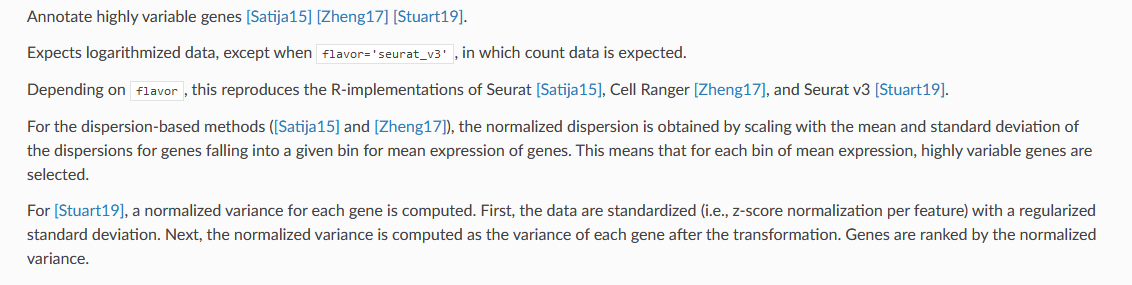
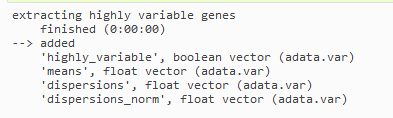
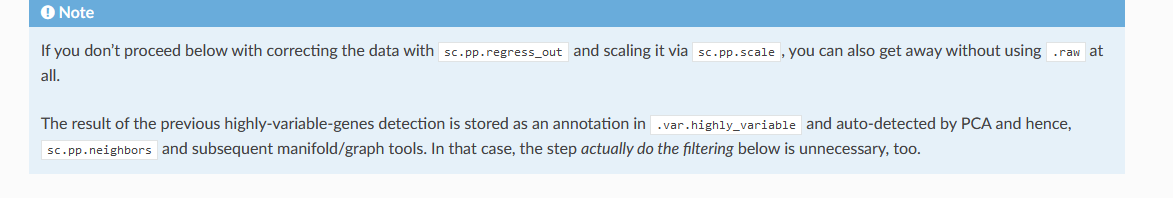



<AxesSubplot:xlabel='mean expressions of genes', ylabel='dispersions of genes (not normalized)'>

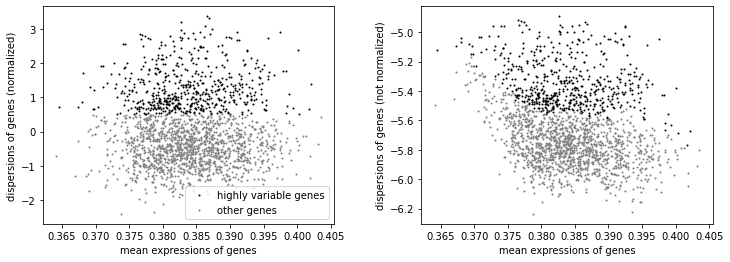

In [18]:
import matplotlib.pyplot as plt
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.pl.highly_variable_genes(adata, show=False) # can not scale only x

## 3. PCA

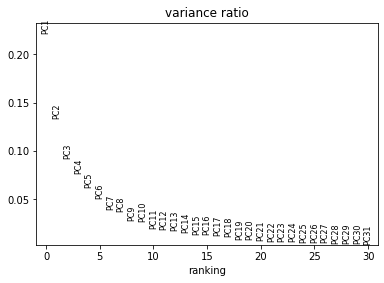

In [19]:
sc.tl.pca(adata, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata)

## 4. Neighborhood graph and umap

In [20]:
from itertools import product
import seaborn as sns
import matplotlib.pyplot as plt

### Select metric

In [22]:
metrics = [  'sokalmichener', 'sokalsneath', 'yule', 'cosine', 'euclidean', 'l1', 'l2', 'manhattan','braycurtis', 'canberra', 'chebyshev', 'correlation', 'dice', 'hamming', 'jaccard', 'kulsinski', 'mahalanobis', 'minkowski', 'rogerstanimoto', 'russellrao']

metric: sokalmichener (0, 0)
metric: sokalsneath (0, 1)
metric: yule (0, 2)
metric: cosine (0, 3)
metric: euclidean (0, 4)
metric: l1 (1, 0)
metric: l2 (1, 1)
metric: manhattan (1, 2)
metric: braycurtis (1, 3)
metric: canberra (1, 4)
metric: chebyshev (2, 0)
metric: correlation (2, 1)
metric: dice (2, 2)
metric: hamming (2, 3)
metric: jaccard (2, 4)
metric: kulsinski (3, 0)
metric: mahalanobis (3, 1)
metric: minkowski (3, 2)
metric: rogerstanimoto (3, 3)
metric: russellrao (3, 4)


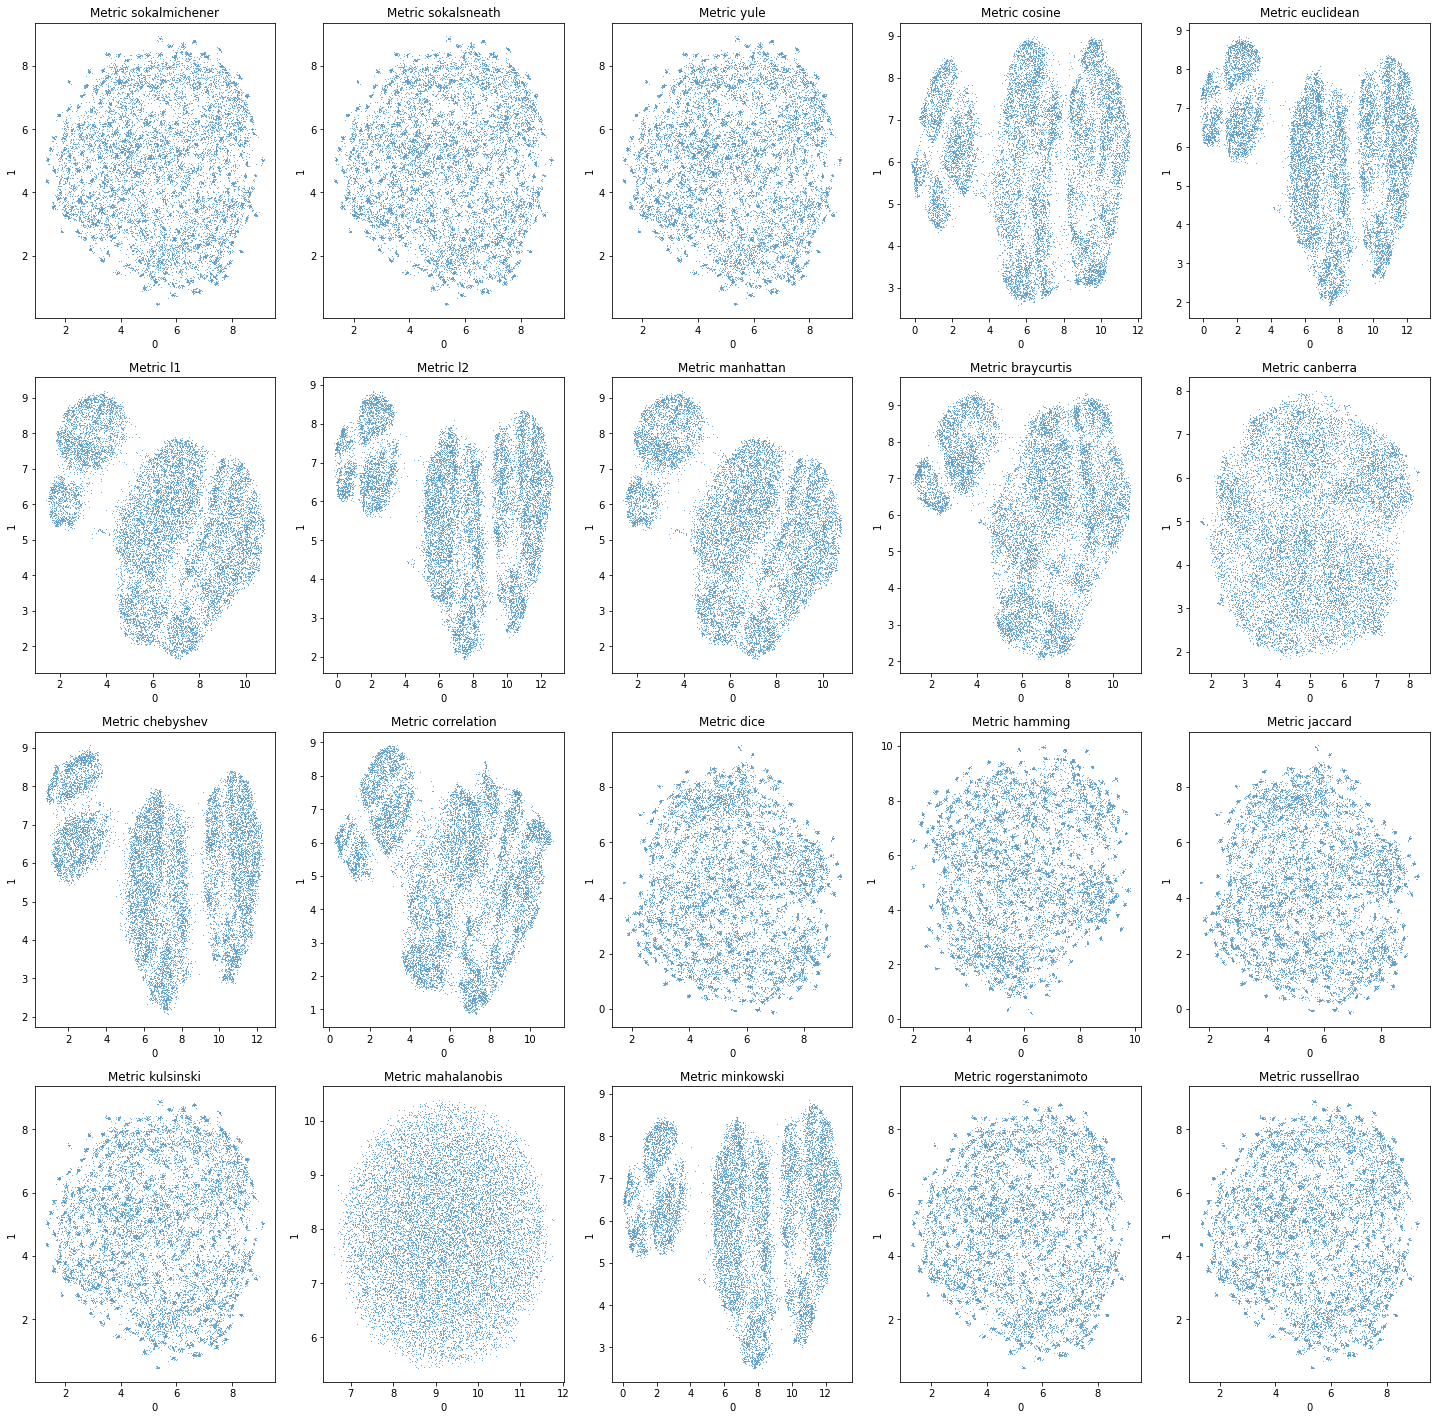

In [23]:
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(25,25))
for coord, metric in zip(product(range(5), range(5)), metrics):
    print("metric:", metric , coord)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric=metric)
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"Metric {metric}")

### Select number of principal components

In [24]:
principal_components = range(5, 30, 5)

In [25]:
list(principal_components)

[5, 10, 15, 20, 25]

In [26]:
len(list(principal_components))

5

n_pcs: 5
n_pcs: 10
n_pcs: 15
n_pcs: 20
n_pcs: 25


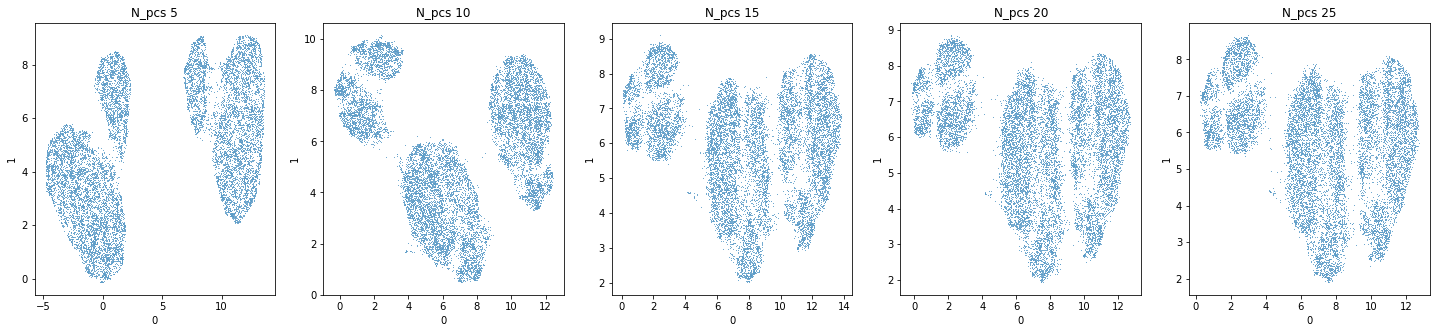

In [27]:
fig, axes = plt.subplots(ncols=5, figsize=(25,5))
for i, n_pcs in enumerate(principal_components):
    print("n_pcs:", n_pcs)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=n_pcs, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[i]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"N_pcs {n_pcs}")

### Select number of neighbours

In [28]:
num_neighbors = range(5, 55, 5)

In [29]:
len(num_neighbors)

10

n_neighbors: 5 (0, 0)
n_neighbors: 10 (0, 1)
n_neighbors: 15 (0, 2)
n_neighbors: 20 (0, 3)
n_neighbors: 25 (0, 4)
n_neighbors: 30 (1, 0)
n_neighbors: 35 (1, 1)
n_neighbors: 40 (1, 2)
n_neighbors: 45 (1, 3)
n_neighbors: 50 (1, 4)


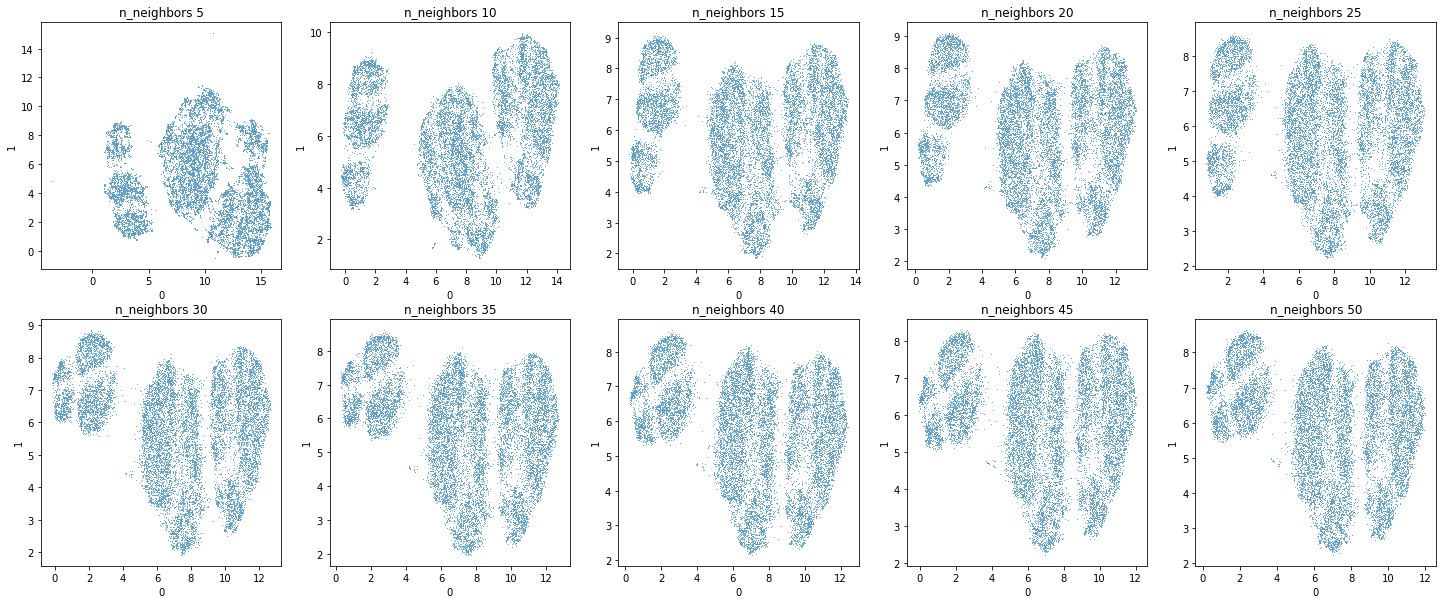

In [30]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, n_neighbors in zip(product(range(2), range(5)), num_neighbors):
    print("n_neighbors:", n_neighbors , coord)
    sc.pp.neighbors(adata, n_neighbors=n_neighbors, n_pcs=20, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"n_neighbors {n_neighbors}")


### Select min_dist

In [31]:
min_dists = np.linspace(0.05, 0.5, 10)

min_dist: 0.05 (0, 0)
min_dist: 0.1 (0, 1)
min_dist: 0.15000000000000002 (0, 2)
min_dist: 0.2 (0, 3)
min_dist: 0.25 (0, 4)
min_dist: 0.3 (1, 0)
min_dist: 0.35000000000000003 (1, 1)
min_dist: 0.4 (1, 2)
min_dist: 0.45 (1, 3)
min_dist: 0.5 (1, 4)


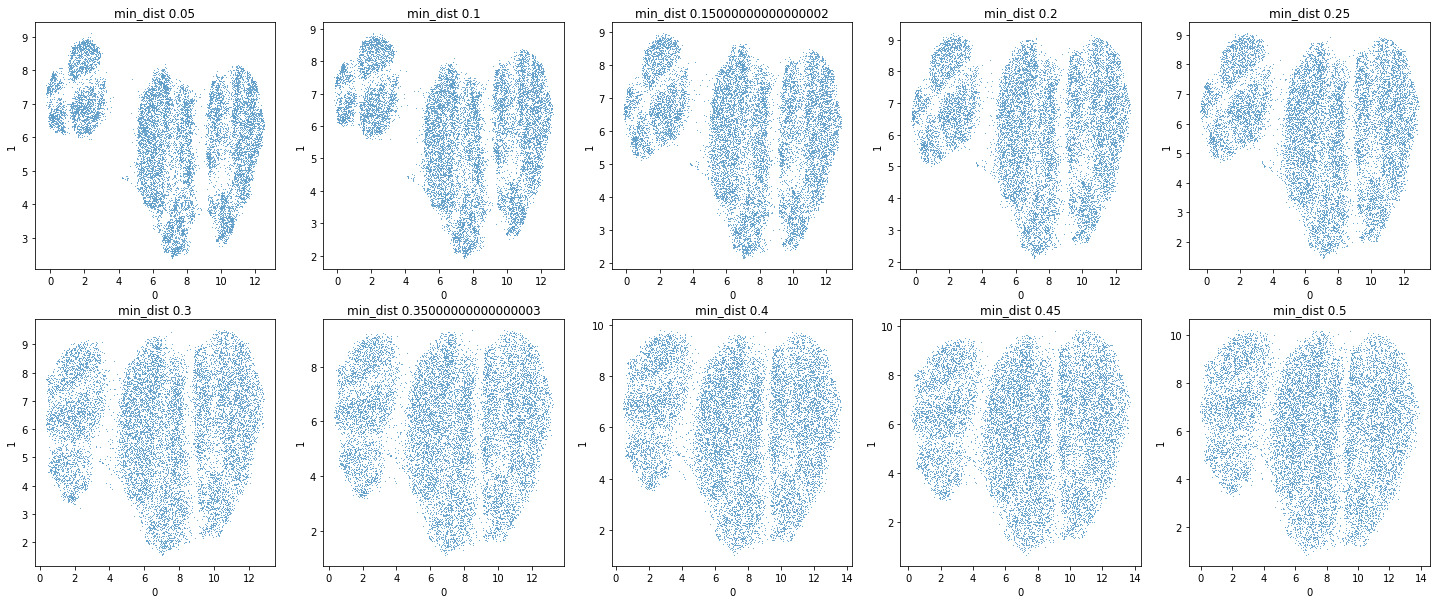

In [32]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, min_dist in zip(product(range(2), range(5)), min_dists):
    print("min_dist:", min_dist , coord)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric='euclidean')
    sc.tl.umap(adata, min_dist=min_dist)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"min_dist {min_dist}")

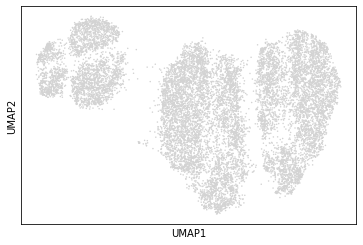

In [33]:
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric="euclidean")
sc.tl.umap(adata, min_dist=0.1)
sc.pl.umap(adata)

## 5.  Cell clusters

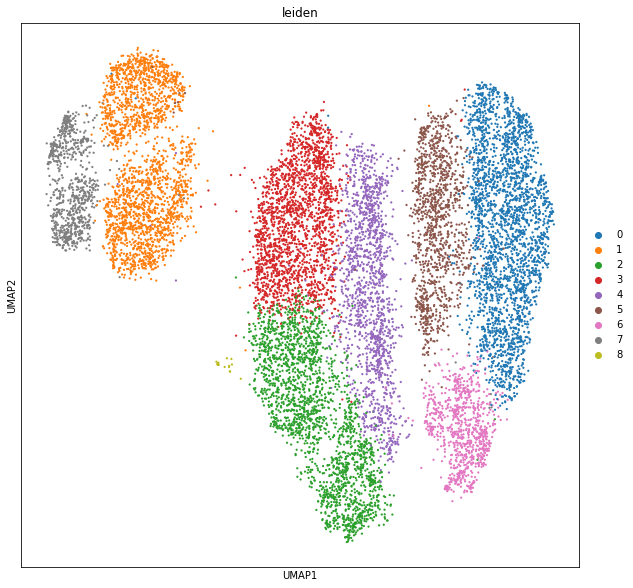

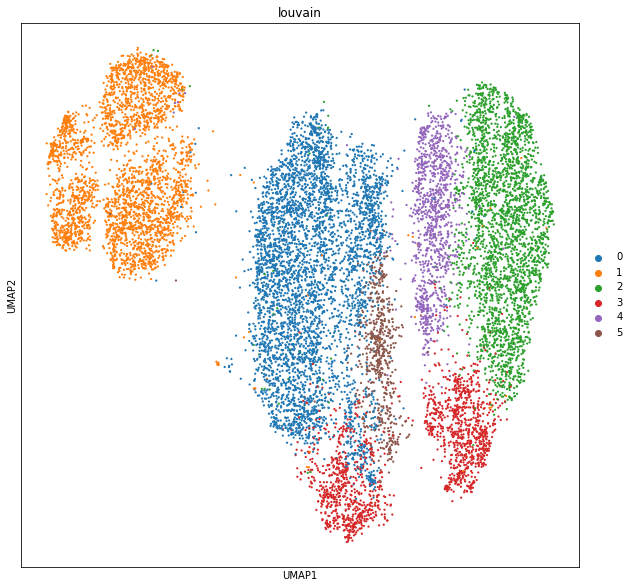

In [217]:
from matplotlib.pyplot import rc_context
with rc_context({'figure.figsize': (10, 10)}):
    sc.tl.leiden(adata, resolution=0.7)
    sc.tl.louvain(adata, resolution=0.7)
    sc.pl.umap(adata, color='leiden', s=20)
    sc.pl.umap(adata, color='louvain', s=20)

<AxesSubplot:xlabel='0', ylabel='1'>

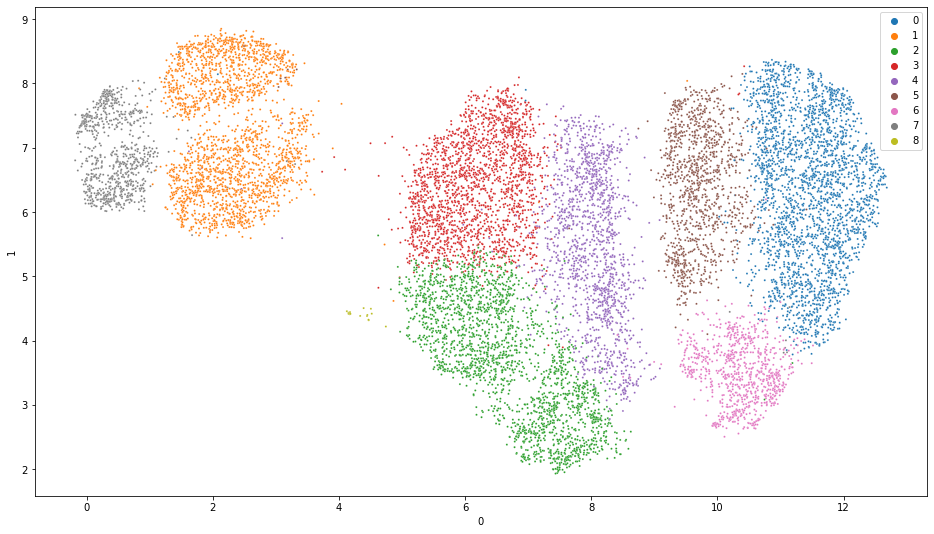

In [195]:
plt.figure(figsize=(16,9))
df = pd.DataFrame(adata.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=4, hue=adata.obs['leiden'].values)

## 6. Color by allele

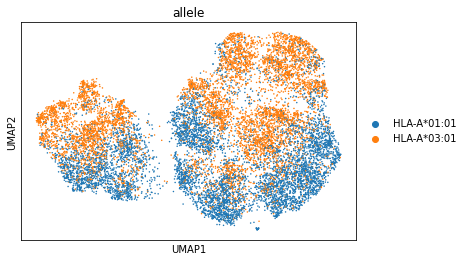

In [167]:
sc.pl.umap(adata, color="allele")

<AxesSubplot:xlabel='0', ylabel='1'>

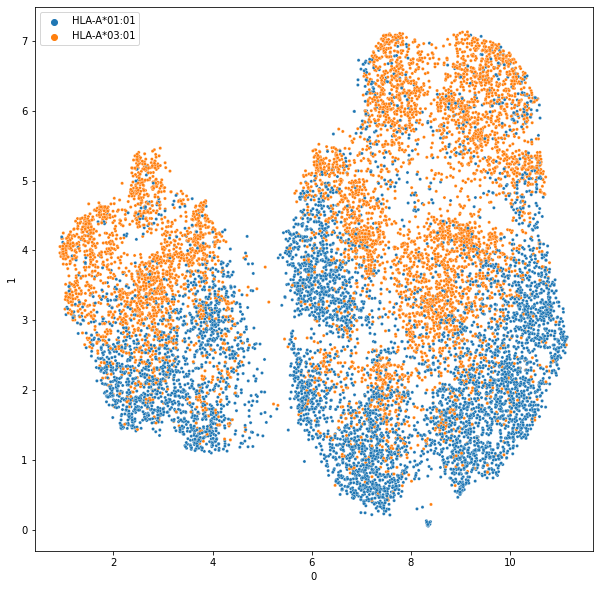

In [168]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=10, hue=adata.obs['allele'].values)

## 7. Plot cluster motifs

In [169]:
peptides_df = adata.obs.copy()

In [170]:
import logomaker
def make_logo(df, length=9, cluster_num=0):
    filtered = df[df['length'] == length]
    matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    counts = dict(df['allele'].value_counts())
    # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
    ww_logo.ax.set_title(f"Cluster {cluster_num} Allele counts: {counts}")

In [171]:
def plot_all_cluster_motifs(source_df, cluster_column = 'leiden' ):
    unique_clusters = peptides_df[cluster_column].unique()
    for cluster_num in unique_clusters:
        df = source_df[source_df[cluster_column] == cluster_num]
        make_logo(df, cluster_num=cluster_num)

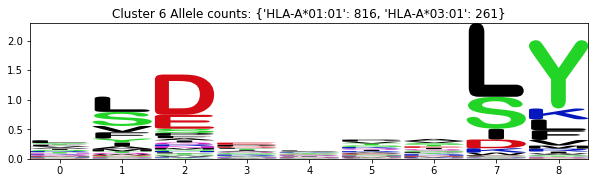

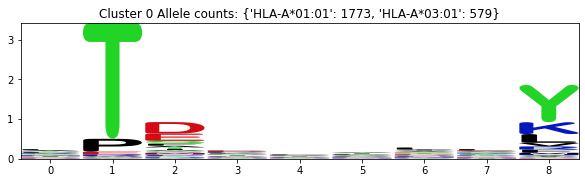

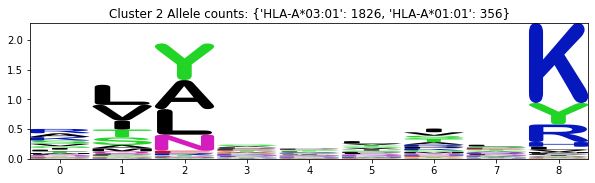

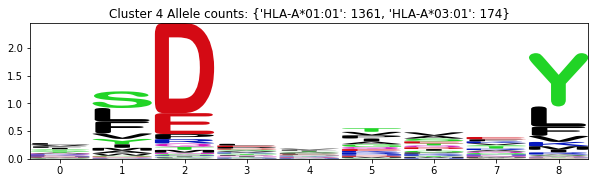

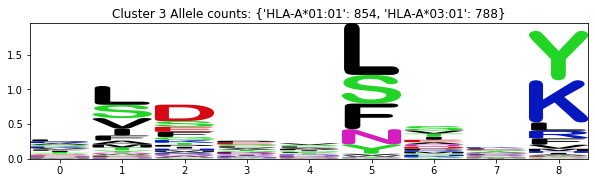

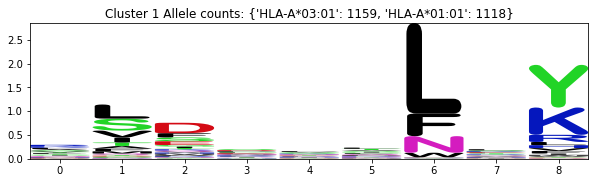

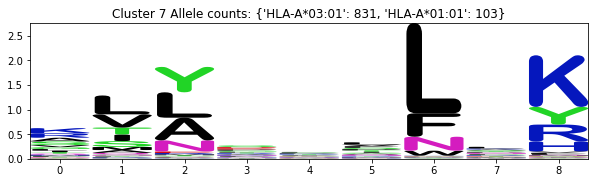

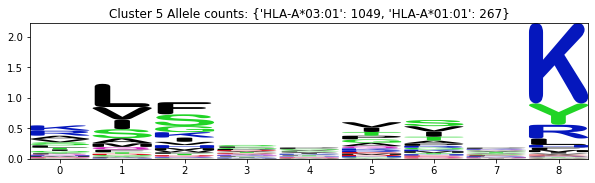

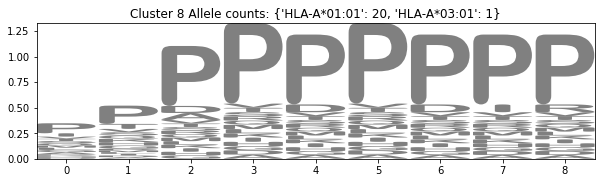

In [172]:
plot_all_cluster_motifs(peptides_df)